# 03 — Preprocessing: Padding, Normalization & Colormap Generation

This is **Phase 4** of the diabetic foot thermography project. Inputs are `manifest.csv` and `subject_metadata.csv`, produced by `01_data_loading_integrity.ipynb` and validated in `02_eda.ipynb`. This notebook does **not** re-parse the raw Excel metadata file and does **not** re-walk the `ThermoDataBase` directory tree — it only opens the individual raw CSV files whose paths are already recorded in `manifest_df` (ordinary file reading, not re-walking).

**Why this notebook exists:** raw thermogram grids have inconsistent shape (per Phase 2/3: height 103–200 px, width 41–88 px), and most downstream models need a fixed-size input. This notebook:

1. Re-verifies the raw shape facts numerically instead of trusting hardcoded numbers carried over from earlier phases.
2. Decides a canonical padded shape (a multiple of 16, for convenience if a conv/pooling model is used later).
3. Centers every full-foot and angiosome grid inside that canonical shape, preserving the parent/angiosome coordinate alignment.
4. Produces **both** a raw (absolute-temperature) array version **and** a relative (per-foot-normalized) array version — directly motivated by the EDA finding that all 12 region-temperature metadata columns are highly collinear (r = 0.81–0.99): overall body/foot temperature dominates raw absolute values, so a relative/differential version is a better candidate primary model input.
5. Renders a fixed-global-color-scale colormap PNG per subject/foot, for visual QA and for use as report figures.

**New dependency: Pillow (PIL).** Earlier notebooks only needed pandas/numpy/matplotlib/scipy/seaborn. We need `PIL.Image.fromarray(...)` here because `plt.savefig()` rasterizes a whole matplotlib *figure* (axes, margins, DPI) and does not guarantee that one array cell maps to exactly one output pixel. `Image.fromarray` writes the RGB array directly, giving an exact `canonical_height x canonical_width` PNG with guaranteed 1:1 pixel correspondence to the array — required here because these PNGs must stay spatially aligned with the angiosome region arrays.


In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import random

import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.colors as mcolors

from PIL import Image

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# Running log of any data-integrity issues found anywhere in this notebook.
# Section 13 (Final Summary) prints this list in full.
issues_log = []

print("Imports OK. RANDOM_SEED =", RANDOM_SEED)


Imports OK. RANDOM_SEED = 42


## Section 1 — Setup

Load the two processed files produced by earlier phases and confirm they loaded correctly (shape + dtypes). Define every output directory as a `Path` object up front — these paths are the *only* things that should need to change if this notebook is run on another machine. All five output directories are created now (idempotently, `exist_ok=True`) so later sections can write to them directly.


In [2]:
print("=== SECTION 1: Setup ===")

# --- Inputs (already-processed; do not re-derive from raw Excel or the raw directory tree) ---
PROCESSED_DIR = Path("data/processed")
MANIFEST_PATH = PROCESSED_DIR / "manifest.csv"
METADATA_PATH = PROCESSED_DIR / "subject_metadata.csv"

manifest_df = pd.read_csv(MANIFEST_PATH)
metadata_df = pd.read_csv(METADATA_PATH)

print(f"manifest_df shape: {manifest_df.shape}")
print(manifest_df.dtypes)
print()
print(f"metadata_df shape: {metadata_df.shape}")
print(metadata_df.dtypes)

# --- Outputs ---
RAW_ARRAYS_DIR = PROCESSED_DIR / "raw_arrays"
MASKS_DIR = RAW_ARRAYS_DIR / "masks"
ANGIOSOMES_DIR = RAW_ARRAYS_DIR / "angiosomes"
RELATIVE_ARRAYS_DIR = PROCESSED_DIR / "relative_arrays"
COLORMAP_PNGS_DIR = PROCESSED_DIR / "colormap_pngs"

OUTPUT_DIRS = [RAW_ARRAYS_DIR, MASKS_DIR, ANGIOSOMES_DIR, RELATIVE_ARRAYS_DIR, COLORMAP_PNGS_DIR]
for d in OUTPUT_DIRS:
    d.mkdir(parents=True, exist_ok=True)
    print(f"Ensured directory exists: {d}")


=== SECTION 1: Setup ===
manifest_df shape: (3340, 9)
group            str
subject_id       str
gender           str
foot_side        str
is_angiosome    bool
region           str
file_type        str
file_stem        str
file_path        str
dtype: object

metadata_df shape: (167, 19)
Subject              str
Gender               str
Age_years        float64
Weight_kg        float64
Height_m         float64
BMI              float64
RIGHT_General    float64
RIGHT_LCA        float64
RIGHT_LPA        float64
RIGHT_MCA        float64
RIGHT_MPA        float64
RIGHT_TCI        float64
LEFT_General     float64
LEFT_LCA         float64
LEFT_LPA         float64
LEFT_MCA         float64
LEFT_MPA         float64
LEFT_TCI         float64
Group                str
dtype: object
Ensured directory exists: data\processed\raw_arrays
Ensured directory exists: data\processed\raw_arrays\masks
Ensured directory exists: data\processed\raw_arrays\angiosomes
Ensured directory exists: data\processed\relative_a

## Section 2 — Shape Re-Verification

Phase 2/3 reported a height range of 103–200 px and a width range of 41–88 px across the 334 full-foot files. We do not trust that number here — every full-foot raw CSV is reloaded from disk (via the paths already in `manifest_df`) and the range is recomputed fresh, as an integrity check that nothing has changed and that this notebook's own file-reading logic agrees with the earlier phases.


In [3]:
print("=== SECTION 2: Shape Re-Verification ===")

full_foot_condition = (manifest_df["is_angiosome"] == False) & (manifest_df["file_type"] == "csv")
full_foot_df = manifest_df.loc[full_foot_condition].reset_index(drop=True)
print(f"Full-foot CSV files found in manifest: {len(full_foot_df)} (expected 334)")
if len(full_foot_df) != 334:
    issues_log.append(f"SECTION 2: expected 334 full-foot CSVs, found {len(full_foot_df)}")

heights, widths = [], []
for _, row in full_foot_df.iterrows():
    arr = np.loadtxt(row["file_path"], delimiter=",", dtype=np.float32)
    heights.append(arr.shape[0])
    widths.append(arr.shape[1])

heights = np.array(heights)
widths = np.array(widths)

print(f"Height (px): min={heights.min()}, max={heights.max()}, mean={heights.mean():.2f}")
print(f"Width  (px): min={widths.min()}, max={widths.max()}, mean={widths.mean():.2f}")


=== SECTION 2: Shape Re-Verification ===
Full-foot CSV files found in manifest: 334 (expected 334)
Height (px): min=103, max=200, mean=149.34
Width  (px): min=41, max=88, mean=64.48


## Section 3 — Canonical Shape Decision

Every grid is padded up to one fixed **canonical shape** so all arrays can later be stacked into a single tensor. The canonical shape must be:

- large enough to contain the largest real grid in the dataset (no cropping), and
- a multiple of 16 in both dimensions — purely for convenience if a conv/pooling-based model is used downstream later (stride-2 pooling can then be applied repeatedly without odd-size edge cases).


In [4]:
print("=== SECTION 3: Canonical Shape Decision ===")

def smallest_multiple_of_16(n):
    return int(np.ceil(n / 16) * 16)

canonical_height = smallest_multiple_of_16(heights.max())
canonical_width = smallest_multiple_of_16(widths.max())

print(f"Raw max height: {heights.max()}  ->  canonical_height: {canonical_height}")
print(f"Raw max width:  {widths.max()}  ->  canonical_width:  {canonical_width}")
print("Canonical shape = smallest multiple of 16 >= the observed max in each dimension, "
      "so every real grid fits without cropping and the array stays convenient for any "
      "future conv/pooling layers.")

CANONICAL_SHAPE = (canonical_height, canonical_width)


=== SECTION 3: Canonical Shape Decision ===
Raw max height: 200  ->  canonical_height: 208
Raw max width:  88  ->  canonical_width:  96
Canonical shape = smallest multiple of 16 >= the observed max in each dimension, so every real grid fits without cropping and the array stays convenient for any future conv/pooling layers.


## Section 4 — Padding Function

A single reusable function that zero-pads a 2D array up to `CANONICAL_SHAPE`, **centering** the original grid rather than anchoring it top-left. Centering avoids introducing a systematic positional bias (a model could otherwise learn "foot pixels are always near the top-left" as a spurious shortcut instead of learning real anatomy). Background fill is `0`, consistent with the dataset's existing 0 = no-tissue convention.


In [5]:
print("=== SECTION 4: Padding Function ===")

def pad_to_canonical(arr, canonical_shape):
    """
    Zero-pad a 2D array to `canonical_shape`, centering the original array.
    Returns (padded_array, row_offset, col_offset).
    """
    h, w = arr.shape
    H, W = canonical_shape
    if h > H or w > W:
        raise ValueError(f"Array shape {arr.shape} exceeds canonical shape {canonical_shape}")

    row_offset = (H - h) // 2
    col_offset = (W - w) // 2

    padded = np.zeros((H, W), dtype=arr.dtype)
    padded[row_offset:row_offset + h, col_offset:col_offset + w] = arr
    return padded, row_offset, col_offset

# Quick self-test on a synthetic array before relying on this for real data.
_test = np.ones((3, 5), dtype=np.float32)
_padded, _ro, _co = pad_to_canonical(_test, (16, 16))
assert _padded.shape == (16, 16)
assert _padded.sum() == _test.sum()
assert np.array_equal(_padded[_ro:_ro + 3, _co:_co + 5], _test)
print("pad_to_canonical() self-test passed.")


=== SECTION 4: Padding Function ===
pad_to_canonical() self-test passed.


## Section 5 — Apply Padding: Full-Foot Arrays

For every one of the 334 full-foot CSVs: load it, pad it to the canonical shape (centered), and save two files — the padded temperature array (`float32 .npy`) and a boolean tissue mask (`True` where the padded array is nonzero). We also record each file's `(subject_id, foot_side, original shape, row_offset, col_offset)` for reuse in later sections — angiosome padding in Section 6 must reuse these exact offsets rather than recomputing its own.


In [6]:
print("=== SECTION 5: Padding Full-Foot Arrays ===")

full_foot_records = []          # list of dicts, one per subject+foot
padded_full_foot = {}           # (subject_id, foot_side) -> padded float32 array (cached in memory)
padded_full_foot_mask = {}      # (subject_id, foot_side) -> boolean tissue mask array (cached in memory)

for _, row in full_foot_df.iterrows():
    subject_id = row["subject_id"]
    foot_side = row["foot_side"]

    arr = np.loadtxt(row["file_path"], delimiter=",", dtype=np.float32)
    padded, row_offset, col_offset = pad_to_canonical(arr, CANONICAL_SHAPE)
    mask = padded != 0

    raw_path = RAW_ARRAYS_DIR / f"{subject_id}_{foot_side}.npy"
    mask_path = MASKS_DIR / f"{subject_id}_{foot_side}_mask.npy"
    np.save(raw_path, padded)
    np.save(mask_path, mask)

    padded_full_foot[(subject_id, foot_side)] = padded
    padded_full_foot_mask[(subject_id, foot_side)] = mask

    full_foot_records.append({
        "subject_id": subject_id,
        "group": row["group"],
        "gender": row["gender"],
        "foot_side": foot_side,
        "original_height": arr.shape[0],
        "original_width": arr.shape[1],
        "pad_row_offset": row_offset,
        "pad_col_offset": col_offset,
        "canonical_height": canonical_height,
        "canonical_width": canonical_width,
        "raw_array_path": str(raw_path),
        "mask_path": str(mask_path),
    })

print(f"Padded and saved {len(full_foot_records)} full-foot arrays + masks "
      f"(expected 334) to {RAW_ARRAYS_DIR} and {MASKS_DIR}")
if len(full_foot_records) != 334:
    issues_log.append(f"SECTION 5: expected 334 full-foot arrays written, got {len(full_foot_records)}")


=== SECTION 5: Padding Full-Foot Arrays ===
Padded and saved 334 full-foot arrays + masks (expected 334) to data\processed\raw_arrays and data\processed\raw_arrays\masks


## Section 6 — Apply Padding: Angiosome Arrays

Each angiosome CSV (LCA/LPA/MCA/MPA) is a same-shape mask of its parent full-foot CSV. To keep it in the exact same coordinate frame as the padded full-foot array, we **reuse the parent's `(row_offset, col_offset)`** recorded in Section 5 rather than recomputing centering independently. Recomputing independently would normally land on the same offset anyway (since shapes match), but reusing the stored value removes any possibility of drift and directly encodes the "same coordinate frame" requirement.


In [7]:
print("=== SECTION 6: Padding Angiosome Arrays ===")

offset_lookup = {
    (r["subject_id"], r["foot_side"]): (r["pad_row_offset"], r["pad_col_offset"], r["original_height"], r["original_width"])
    for r in full_foot_records
}

angiosome_condition = (manifest_df["is_angiosome"] == True) & (manifest_df["file_type"] == "csv")
angiosome_df = manifest_df.loc[angiosome_condition].reset_index(drop=True)
print(f"Angiosome CSV files found in manifest: {len(angiosome_df)} (expected 1336)")
if len(angiosome_df) != 1336:
    issues_log.append(f"SECTION 6: expected 1336 angiosome CSVs, found {len(angiosome_df)}")

angiosome_written = 0
shape_mismatches = 0

for _, row in angiosome_df.iterrows():
    subject_id = row["subject_id"]
    foot_side = row["foot_side"]
    region = row["region"]

    key = (subject_id, foot_side)
    if key not in offset_lookup:
        issues_log.append(f"SECTION 6: no parent full-foot offset found for {subject_id}_{foot_side}_{region}")
        continue
    row_offset, col_offset, parent_h, parent_w = offset_lookup[key]

    arr = np.loadtxt(row["file_path"], delimiter=",", dtype=np.float32)
    if arr.shape != (parent_h, parent_w):
        shape_mismatches += 1
        issues_log.append(
            f"SECTION 6: angiosome {subject_id}_{foot_side}_{region} shape {arr.shape} "
            f"!= parent full-foot shape ({parent_h}, {parent_w})"
        )
        continue

    padded = np.zeros(CANONICAL_SHAPE, dtype=np.float32)
    h, w = arr.shape
    padded[row_offset:row_offset + h, col_offset:col_offset + w] = arr

    out_path = ANGIOSOMES_DIR / f"{subject_id}_{foot_side}_{region}.npy"
    np.save(out_path, padded)
    angiosome_written += 1

print(f"Padded and saved {angiosome_written} angiosome arrays (expected 1336) to {ANGIOSOMES_DIR}")
print(f"Shape mismatches vs. parent (skipped): {shape_mismatches}")


=== SECTION 6: Padding Angiosome Arrays ===
Angiosome CSV files found in manifest: 1336 (expected 1336)
Padded and saved 1336 angiosome arrays (expected 1336) to data\processed\raw_arrays\angiosomes
Shape mismatches vs. parent (skipped): 0


## Section 7 — Post-Padding Integrity Check

Phase 2 validated that every nonzero pixel in a raw angiosome CSV is also nonzero at the same coordinate in its parent raw full-foot CSV. That subset relationship must still hold after padding, since padding only adds zeros around the edges and should not move any pixel's relative position. This is re-verified here on the actual **saved, padded** `.npy` files (re-loaded from disk, not from the in-memory variables above), so this check also catches any save/load bug, not just a logic bug.


In [8]:
print("=== SECTION 7: Post-Padding Integrity Check ===")

checked = 0
passed = 0
failures = []

for _, row in angiosome_df.iterrows():
    subject_id = row["subject_id"]
    foot_side = row["foot_side"]
    region = row["region"]

    angiosome_path = ANGIOSOMES_DIR / f"{subject_id}_{foot_side}_{region}.npy"
    parent_path = RAW_ARRAYS_DIR / f"{subject_id}_{foot_side}.npy"

    if not angiosome_path.exists() or not parent_path.exists():
        failures.append(f"{subject_id}_{foot_side}_{region}: missing file(s) on disk")
        continue

    angiosome_arr = np.load(angiosome_path)
    parent_arr = np.load(parent_path)

    checked += 1
    angiosome_nonzero = angiosome_arr != 0
    subset_ok = np.all(parent_arr[angiosome_nonzero] != 0)

    if subset_ok:
        passed += 1
    else:
        n_bad = int(np.sum(angiosome_nonzero & (parent_arr == 0)))
        failures.append(f"{subject_id}_{foot_side}_{region}: {n_bad} nonzero angiosome pixels are zero in parent")

print(f"Checked: {checked} | Passed: {passed} | Failed: {len(failures)}")

if failures:
    print("--- FAILURE DETAILS ---")
    for f in failures:
        print(" -", f)
    issues_log.extend(f"SECTION 7: {f}" for f in failures)
else:
    print("All angiosome/full-foot subset relationships hold after padding. 0 failures.")


=== SECTION 7: Post-Padding Integrity Check ===
Checked: 1336 | Passed: 1336 | Failed: 0
All angiosome/full-foot subset relationships hold after padding. 0 failures.


## Section 8 — Relative (Normalized) Arrays

The EDA notebook found all 12 region-temperature metadata columns highly correlated (r = 0.81–0.99): raw absolute temperature is dominated by each subject's overall body/foot temperature level, not by spatial pattern. To give later modeling phases a feature that isolates *spatial pattern* independent of that per-subject level, we compute, for every padded full-foot array, the mean temperature over its own tissue pixels (using the Section 5 mask), then subtract that mean from every tissue pixel. Background stays exactly `0` (not `0 - mean`), so the 0 = background convention is preserved in the relative array too.


In [9]:
print("=== SECTION 8: Relative (Normalized) Arrays ===")

relative_paths = {}
relative_mins, relative_maxs, relative_means = [], [], []

for key, padded in padded_full_foot.items():
    subject_id, foot_side = key
    mask = padded_full_foot_mask[key]

    tissue_mean = padded[mask].mean()
    relative = np.zeros_like(padded)
    relative[mask] = padded[mask] - tissue_mean

    out_path = RELATIVE_ARRAYS_DIR / f"{subject_id}_{foot_side}.npy"
    np.save(out_path, relative)
    relative_paths[key] = str(out_path)

    relative_mins.append(relative[mask].min())
    relative_maxs.append(relative[mask].max())
    relative_means.append(relative[mask].mean())

print(f"Saved {len(relative_paths)} relative arrays (expected 334) to {RELATIVE_ARRAYS_DIR}")
if len(relative_paths) != 334:
    issues_log.append(f"SECTION 8: expected 334 relative arrays written, got {len(relative_paths)}")

relative_mins = np.array(relative_mins)
relative_maxs = np.array(relative_maxs)
relative_means = np.array(relative_means)

print("Per-array tissue-pixel relative value ranges across the dataset:")
print(f"  min of mins:  {relative_mins.min():.3f}")
print(f"  max of maxs:  {relative_maxs.max():.3f}")
print(f"  mean of means (should be ~0 by construction): {relative_means.mean():.6f}")


=== SECTION 8: Relative (Normalized) Arrays ===
Saved 334 relative arrays (expected 334) to data\processed\relative_arrays
Per-array tissue-pixel relative value ranges across the dataset:
  min of mins:  -11.004
  max of maxs:  5.187
  mean of means (should be ~0 by construction): -0.000000


## Section 9 — Global Color Scale

Every colormap PNG must use the **same** color-to-temperature mapping so that color is directly comparable across the whole dataset — unlike the original dataset's PNGs, which were auto-scaled per-subject and so are not visually comparable to each other. One global `(min, max)` is computed over every nonzero (tissue) pixel across all 334 padded full-foot arrays, and used for every PNG in Section 10.


In [10]:
print("=== SECTION 9: Global Color Scale ===")

global_min = np.inf
global_max = -np.inf

for key, padded in padded_full_foot.items():
    mask = padded_full_foot_mask[key]
    tissue_vals = padded[mask]
    if tissue_vals.size == 0:
        continue
    global_min = min(global_min, float(tissue_vals.min()))
    global_max = max(global_max, float(tissue_vals.max()))

print(f"Global nonzero temperature min: {global_min:.4f} C")
print(f"Global nonzero temperature max: {global_max:.4f} C")
print("This fixed (min, max) range is used to normalize every colormap PNG in Section 10.")


=== SECTION 9: Global Color Scale ===
Global nonzero temperature min: 15.9770 C
Global nonzero temperature max: 37.2790 C
This fixed (min, max) range is used to normalize every colormap PNG in Section 10.


## Section 10 — Colormap PNG Generation

For every padded full-foot array, each **tissue** pixel's temperature is mapped to an RGB color via matplotlib's `jet` colormap, normalized against the **global** min/max from Section 9 (not each array's own min/max). Background pixels are forced to a fixed neutral white `(255, 255, 255)`, a value `jet` itself never produces, so background is always visually distinguishable from real data.

The PNG is built with `PIL.Image.fromarray(...)` rather than `plt.savefig(...)` — see the notebook intro for why exact pixel correspondence matters here.


In [11]:
print("=== SECTION 10: Colormap PNG Generation ===")

jet_cmap = mpl.colormaps["jet"]
norm = mcolors.Normalize(vmin=global_min, vmax=global_max, clip=True)

colormap_paths = {}

for key, padded in padded_full_foot.items():
    subject_id, foot_side = key
    mask = padded_full_foot_mask[key]

    normalized = norm(padded)                      # values in [0, 1], shape (H, W)
    rgba = jet_cmap(normalized)                     # shape (H, W, 4), float in [0, 1]
    rgb = (rgba[:, :, :3] * 255).astype(np.uint8)   # shape (H, W, 3)
    rgb[~mask] = [255, 255, 255]                    # force background to neutral white

    img = Image.fromarray(rgb, mode="RGB")
    out_path = COLORMAP_PNGS_DIR / f"{subject_id}_{foot_side}.png"
    img.save(out_path)
    colormap_paths[key] = str(out_path)

    assert img.size == (canonical_width, canonical_height), (
        f"{subject_id}_{foot_side}: PNG size {img.size} != expected "
        f"({canonical_width}, {canonical_height})"
    )

print(f"Saved {len(colormap_paths)} colormap PNGs (expected 334) to {COLORMAP_PNGS_DIR}")
if len(colormap_paths) != 334:
    issues_log.append(f"SECTION 10: expected 334 colormap PNGs written, got {len(colormap_paths)}")
print(f"Every PNG confirmed to be exactly {canonical_width} x {canonical_height} pixels "
      f"(1:1 pixel correspondence with the padded array).")


=== SECTION 10: Colormap PNG Generation ===
Saved 334 colormap PNGs (expected 334) to data\processed\colormap_pngs
Every PNG confirmed to be exactly 96 x 208 pixels (1:1 pixel correspondence with the padded array).


## Section 11 — Output Manifest

One row per `subject_id + foot_side` (334 rows), recording everything a later phase needs to load this preprocessed data without redoing any of the work above: original shape, padding offsets, canonical shape, and the path to each of the four output artifacts for that subject/foot.


In [12]:
print("=== SECTION 11: Output Manifest ===")

manifest_rows = []
for r in full_foot_records:
    key = (r["subject_id"], r["foot_side"])
    manifest_rows.append({
        "subject_id": r["subject_id"],
        "group": r["group"],
        "gender": r["gender"],
        "foot_side": r["foot_side"],
        "original_height": r["original_height"],
        "original_width": r["original_width"],
        "pad_row_offset": r["pad_row_offset"],
        "pad_col_offset": r["pad_col_offset"],
        "canonical_height": r["canonical_height"],
        "canonical_width": r["canonical_width"],
        "raw_array_path": r["raw_array_path"],
        "mask_path": r["mask_path"],
        "relative_array_path": relative_paths.get(key, ""),
        "colormap_png_path": colormap_paths.get(key, ""),
    })

preprocessing_manifest_df = pd.DataFrame(manifest_rows)
print(f"preprocessing_manifest_df shape: {preprocessing_manifest_df.shape} (expected (334, 14))")
if preprocessing_manifest_df.shape != (334, 14):
    issues_log.append(
        f"SECTION 11: expected preprocessing_manifest_df shape (334, 14), got {preprocessing_manifest_df.shape}"
    )

OUT_MANIFEST_PATH = PROCESSED_DIR / "preprocessing_manifest.csv"
preprocessing_manifest_df.to_csv(OUT_MANIFEST_PATH, index=False)
print(f"Saved to {OUT_MANIFEST_PATH}")
preprocessing_manifest_df.head()


=== SECTION 11: Output Manifest ===
preprocessing_manifest_df shape: (334, 14) (expected (334, 14))
Saved to data\processed\preprocessing_manifest.csv


,subject_id,group,gender,foot_side,original_height,original_width,pad_row_offset,pad_col_offset,canonical_height,canonical_width,raw_array_path,mask_path,relative_array_path,colormap_png_path
0,CG001,Control,M,L,168,65,20,15,208,96,data\processed\raw_arrays\CG001_L.npy,data\processed\raw_arrays\masks\CG001_L_mask.npy,data\processed\relative_arrays\CG001_L.npy,data\processed\colormap_pngs\CG001_L.png
1,CG001,Control,M,R,175,63,16,16,208,96,data\processed\raw_arrays\CG001_R.npy,data\processed\raw_arrays\masks\CG001_R_mask.npy,data\processed\relative_arrays\CG001_R.npy,data\processed\colormap_pngs\CG001_R.png
2,CG002,Control,M,L,179,69,14,13,208,96,data\processed\raw_arrays\CG002_L.npy,data\processed\raw_arrays\masks\CG002_L_mask.npy,data\processed\relative_arrays\CG002_L.npy,data\processed\colormap_pngs\CG002_L.png
3,CG002,Control,M,R,179,69,14,13,208,96,data\processed\raw_arrays\CG002_R.npy,data\processed\raw_arrays\masks\CG002_R_mask.npy,data\processed\relative_arrays\CG002_R.npy,data\processed\colormap_pngs\CG002_R.png
4,CG003,Control,M,L,194,72,7,12,208,96,data\processed\raw_arrays\CG003_L.npy,data\processed\raw_arrays\masks\CG003_L_mask.npy,data\processed\relative_arrays\CG003_L.npy,data\processed\colormap_pngs\CG003_L.png


## Section 12 — Visual Sanity Check

For 2 random Control and 2 random DM subjects (`RANDOM_SEED = 42`, same convention as `02_eda.ipynb`), this shows, side by side: the original raw CSV (zeros masked as `NaN` so background doesn't visually dominate the color scale), the padded array, and the colormap PNG **loaded back from disk** — so both the padding step and the coloring step can be visually confirmed correct and undistorted. Each subject's **left foot** is used, consistent with the visualization convention already established in `02_eda.ipynb`.


=== SECTION 12: Visual Sanity Check ===
Sampled subjects: ['CG041', 'CG008', 'DM004', 'DM095']


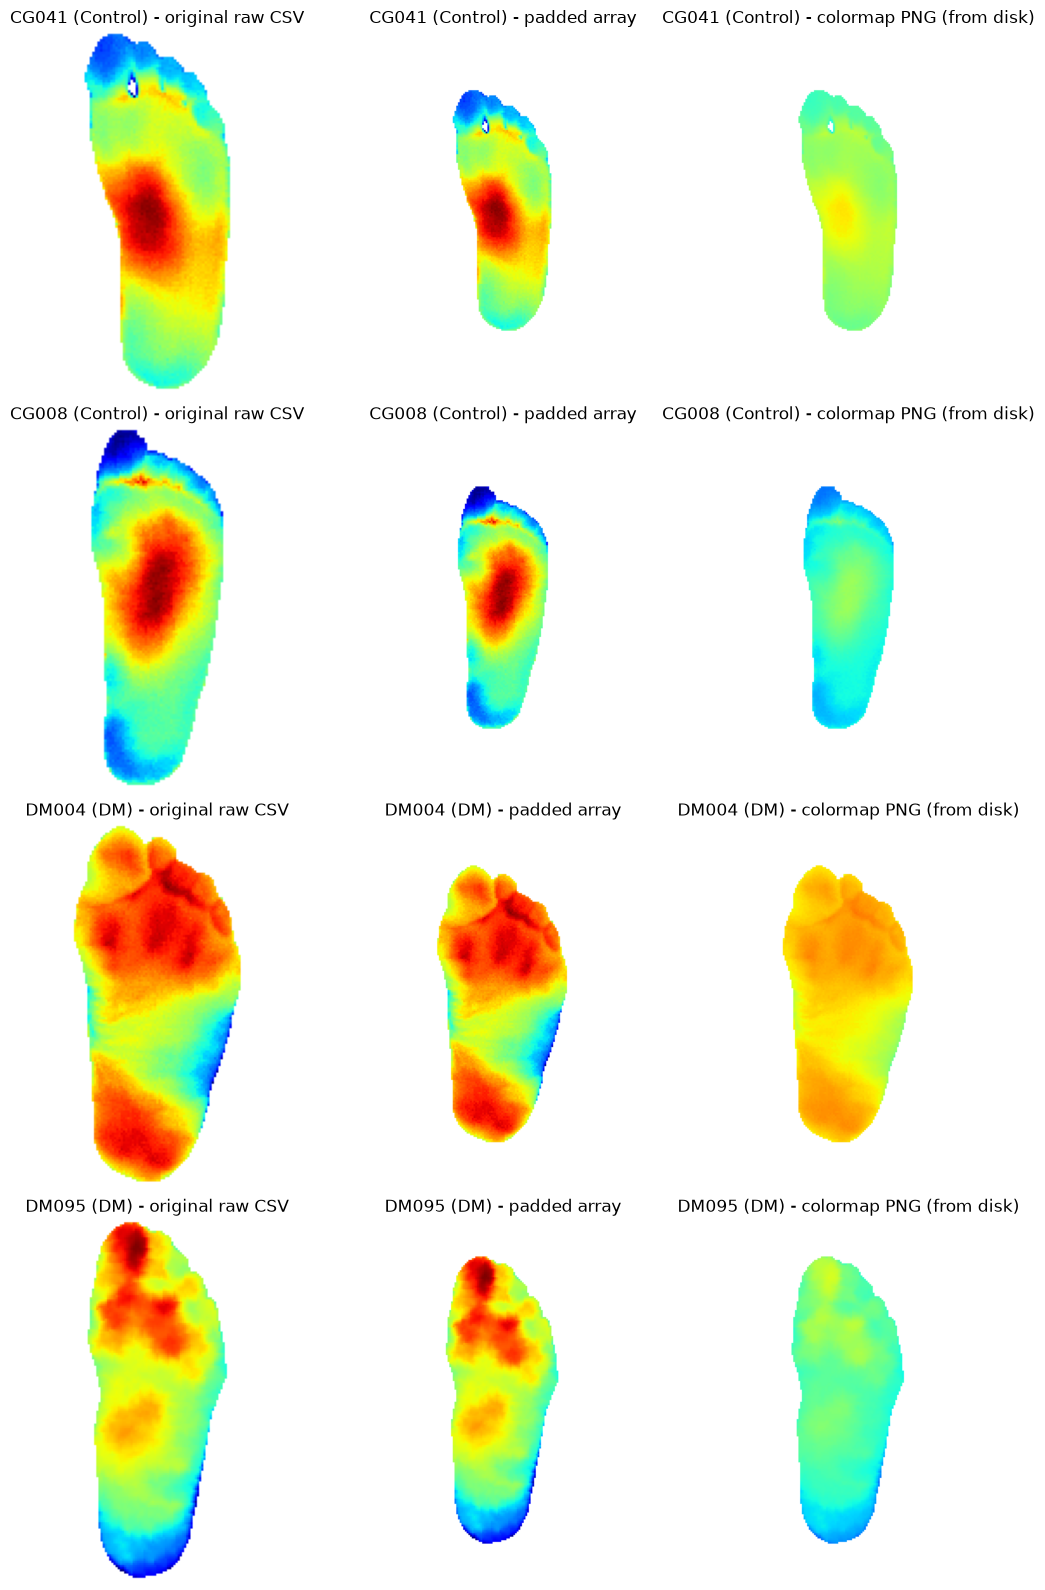

In [13]:
print("=== SECTION 12: Visual Sanity Check ===")

random.seed(RANDOM_SEED)

control_subjects = sorted(metadata_df.loc[metadata_df["Group"] == "Control", "Subject"].unique())
dm_subjects = sorted(metadata_df.loc[metadata_df["Group"] == "DM", "Subject"].unique())

sample_subjects = random.sample(control_subjects, 2) + random.sample(dm_subjects, 2)
print("Sampled subjects:", sample_subjects)

FOOT_SIDE_FOR_CHECK = "L"

fig, axes = plt.subplots(len(sample_subjects), 3, figsize=(12, 4 * len(sample_subjects)))

for i, subject_id in enumerate(sample_subjects):
    key = (subject_id, FOOT_SIDE_FOR_CHECK)
    group = metadata_df.loc[metadata_df["Subject"] == subject_id, "Group"].values[0]

    # (1) Original raw CSV, straight from manifest_df's file_path, zeros -> NaN
    raw_row = manifest_df[
        (manifest_df["subject_id"] == subject_id)
        & (manifest_df["foot_side"] == FOOT_SIDE_FOR_CHECK)
        & (manifest_df["is_angiosome"] == False)
        & (manifest_df["file_type"] == "csv")
    ].iloc[0]
    original_arr = np.loadtxt(raw_row["file_path"], delimiter=",", dtype=np.float32)
    original_masked = np.where(original_arr == 0, np.nan, original_arr)

    axes[i, 0].imshow(original_masked, cmap="jet")
    axes[i, 0].set_title(f"{subject_id} ({group}) - original raw CSV")
    axes[i, 0].axis("off")

    # (2) Padded array (same array already written to disk in Section 5)
    padded_arr = padded_full_foot[key]
    padded_masked = np.where(padded_arr == 0, np.nan, padded_arr)

    axes[i, 1].imshow(padded_masked, cmap="jet")
    axes[i, 1].set_title(f"{subject_id} ({group}) - padded array")
    axes[i, 1].axis("off")

    # (3) Colormap PNG, loaded back from disk (not from memory) to confirm the saved file itself
    png_path = colormap_paths[key]
    png_img = np.array(Image.open(png_path))

    axes[i, 2].imshow(png_img)
    axes[i, 2].set_title(f"{subject_id} ({group}) - colormap PNG (from disk)")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()


## Section 13 — Final Summary


In [14]:
print("=== SECTION 13: Final Summary ===")

raw_array_count = len(list(RAW_ARRAYS_DIR.glob("*.npy")))
mask_count = len(list(MASKS_DIR.glob("*.npy")))
angiosome_count = len(list(ANGIOSOMES_DIR.glob("*.npy")))
relative_count = len(list(RELATIVE_ARRAYS_DIR.glob("*.npy")))
colormap_count = len(list(COLORMAP_PNGS_DIR.glob("*.png")))

expected = {
    "raw_arrays (.npy)": (raw_array_count, 334),
    "masks (.npy)": (mask_count, 334),
    "angiosome arrays (.npy)": (angiosome_count, 1336),
    "relative_arrays (.npy)": (relative_count, 334),
    "colormap_pngs (.png)": (colormap_count, 334),
}

print("--- File counts ---")
for label, (actual, exp) in expected.items():
    status = "OK" if actual == exp else "MISMATCH"
    print(f"  {label}: {actual} (expected {exp}) [{status}]")
    if actual != exp:
        issues_log.append(f"SECTION 13: {label} count {actual} != expected {exp}")

print()
print(f"preprocessing_manifest.csv shape: {preprocessing_manifest_df.shape} (expected (334, 14))")

print()
print(f"Canonical shape used: {CANONICAL_SHAPE} (height, width)")
print(f"Global color scale used for all colormap PNGs: min={global_min:.4f} C, max={global_max:.4f} C")

print()
print("--- Integrity issues found across Sections 2-13 ---")
if issues_log:
    for issue in issues_log:
        print(" -", issue)
else:
    print("0 issues found.")


=== SECTION 13: Final Summary ===
--- File counts ---
  raw_arrays (.npy): 334 (expected 334) [OK]
  masks (.npy): 334 (expected 334) [OK]
  angiosome arrays (.npy): 1336 (expected 1336) [OK]
  relative_arrays (.npy): 334 (expected 334) [OK]
  colormap_pngs (.png): 334 (expected 334) [OK]

preprocessing_manifest.csv shape: (334, 14) (expected (334, 14))

Canonical shape used: (208, 96) (height, width)
Global color scale used for all colormap PNGs: min=15.9770 C, max=37.2790 C

--- Integrity issues found across Sections 2-13 ---
0 issues found.
